## Initialization

## Load Data

The dataset is stored in the `/datasets/faces/` folder, there you can find
- The `final_files` folder with 7.6k photos
- The `labels.csv` file with labels, with two columns: `file_name` and `real_age`

Given the fact that the number of image files is rather high, it is advisable to avoid reading them all at once, which would greatly consume computational resources. We recommend you build a generator with the ImageDataGenerator generator. This method was explained in Chapter 3, Lesson 7 of this course.

The label file can be loaded as an usual CSV file.

In [2]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from tensorflow.keras.preprocessing.image import ImageDataGenerator

LABELS_PATH = '/datasets/faces/labels.csv'
IMAGES_PATH = '/datasets/faces/final_files/'

labels = pd.read_csv(LABELS_PATH)

print('labels.csv shape:', labels.shape)
print('files on disk:   ', len(os.listdir(IMAGES_PATH)))
print()
labels.info()
labels.head()

labels.csv shape: (7591, 2)
files on disk:    7591

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_name  7591 non-null   object
 1   real_age   7591 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 118.7+ KB


,file_name,real_age
0,000000.jpg,4
1,000001.jpg,18
2,000002.jpg,80
3,000003.jpg,50
4,000004.jpg,17


## EDA

count    7591.000000
mean       31.201159
std        17.145060
min         1.000000
25%        20.000000
50%        29.000000
75%        41.000000
max       100.000000
Name: real_age, dtype: float64

duplicated file_name rows: 0
min age: 1  max age: 100


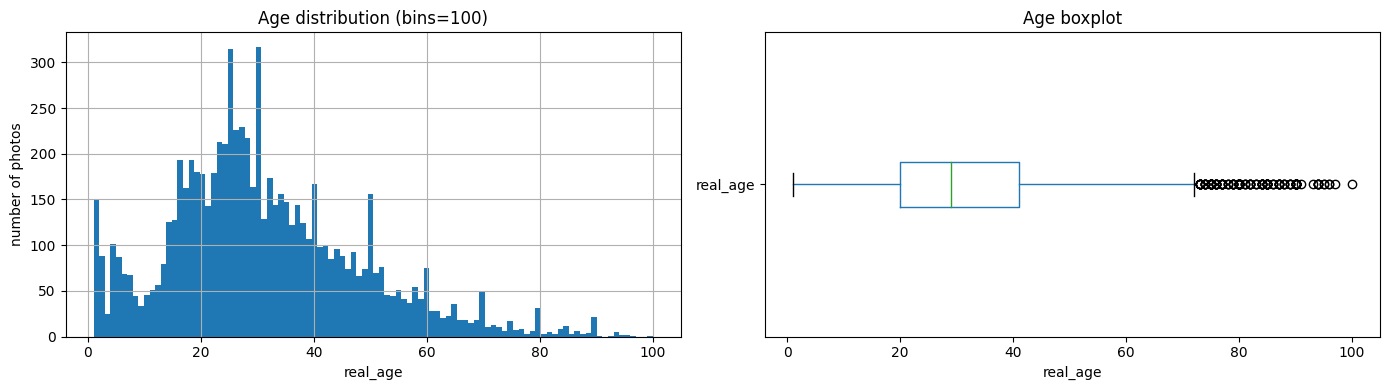


share of the dataset by age bucket, %
real_age
[0, 10)       8.7
[10, 20)     16.0
[20, 30)     27.3
[30, 40)     20.6
[40, 50)     12.4
[50, 60)      8.1
[60, 70)      3.7
[70, 80)      1.7
[80, 101)     1.5
Name: real_age, dtype: float64


In [3]:
# Age distribution

print(labels['real_age'].describe())
print()
print('duplicated file_name rows:', labels['file_name'].duplicated().sum())
print('min age:', labels['real_age'].min(), ' max age:', labels['real_age'].max())

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

labels['real_age'].hist(bins=100, ax=ax[0])
ax[0].set_title('Age distribution (bins=100)')
ax[0].set_xlabel('real_age')
ax[0].set_ylabel('number of photos')

labels['real_age'].plot(kind='box', vert=False, ax=ax[1])
ax[1].set_title('Age boxplot')
ax[1].set_xlabel('real_age')

plt.tight_layout()
plt.show()

bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 101]
age_bucket = pd.cut(labels['real_age'], bins=bins, right=False)
share = (labels.groupby(age_bucket)['real_age'].count() / len(labels) * 100).round(1)
print()
print('share of the dataset by age bucket, %')
print(share)

In [4]:
# Image properties on a random sample of 500 files

rng = np.random.RandomState(12345)
sample_names = rng.choice(labels['file_name'].values, size=500, replace=False)

sizes = []
modes = []
for name in sample_names:
    with Image.open(IMAGES_PATH + name) as im:
        sizes.append(im.size)
        modes.append(im.mode)

print('most common sizes in the sample:')
print(pd.Series(sizes).value_counts().head())
print()
print('smallest side seen:', min(min(s) for s in sizes))
print('largest side seen: ', max(max(s) for s in sizes))
print()
print('color modes in the sample:', pd.Series(modes).value_counts().to_dict())

most common sizes in the sample:
(331, 331)    4
(176, 176)    3
(178, 177)    3
(516, 516)    3
(131, 131)    3
dtype: int64

smallest side seen: 57
largest side seen:  3008

color modes in the sample: {'RGB': 500}


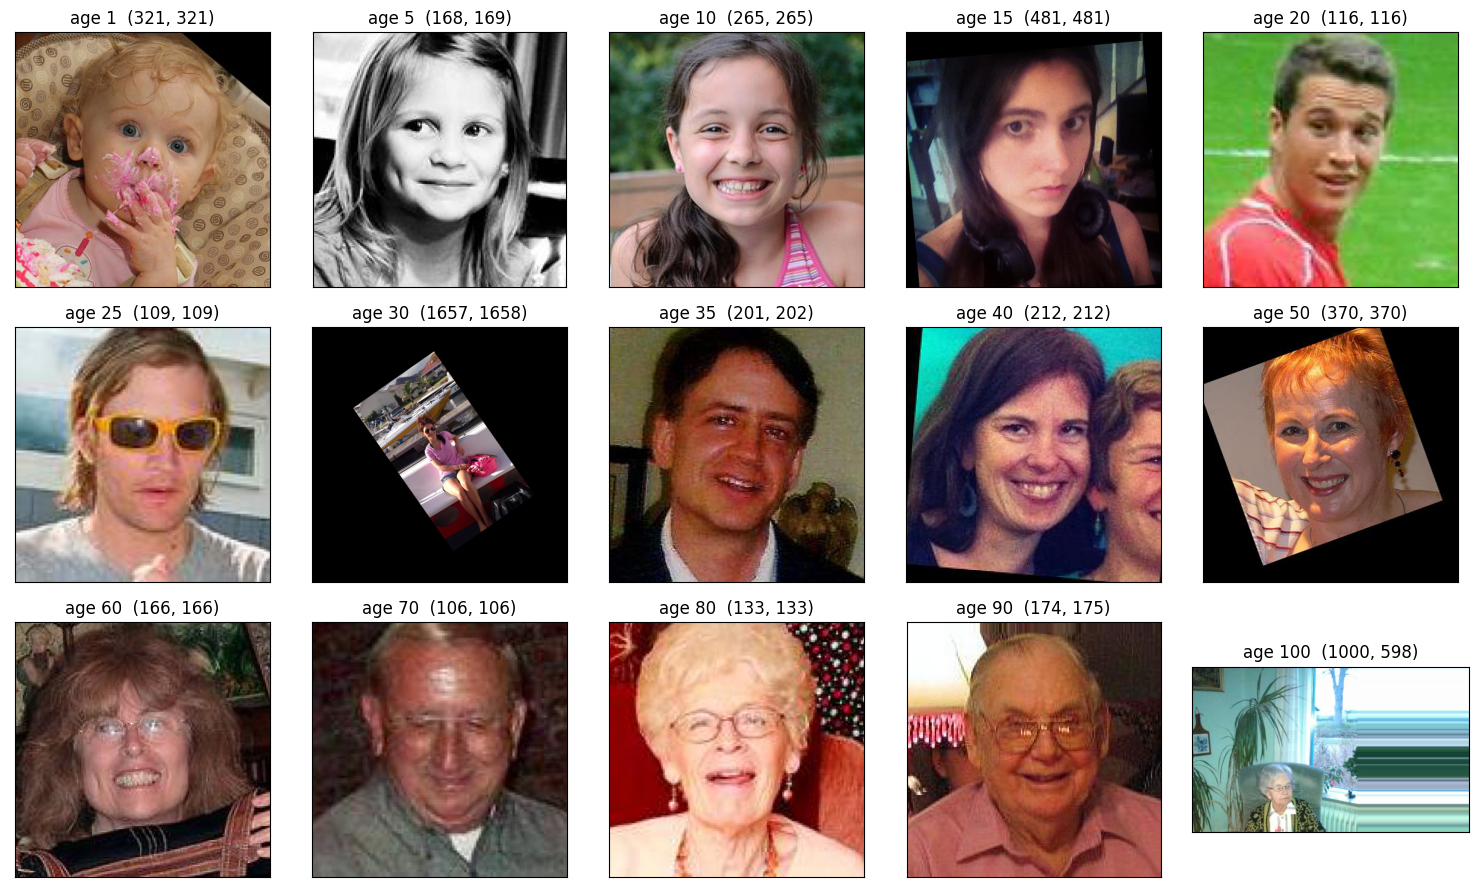

In [5]:
# 15 photos spread across the whole age range

target_ages = [1, 5, 10, 15, 20, 25, 30, 35, 40, 50, 60, 70, 80, 90, 100]

fig = plt.figure(figsize=(15, 9))

for i, age in enumerate(target_ages):
    subset = labels[labels['real_age'] == age]
    if len(subset) == 0:
        continue
    row = subset.iloc[0]
    img = Image.open(IMAGES_PATH + row['file_name'])
    ax = fig.add_subplot(3, 5, i + 1)
    ax.imshow(img)
    ax.set_title('age ' + str(int(row['real_age'])) + '  ' + str(img.size))
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

### Findings

**Dataset size**

- 7591 labelled photos in `labels.csv` and 7591 files in `final_files/`, so every label has exactly one image.
- No missing values and no duplicated `file_name` values.

**Age distribution**

- Range is 1 to 100. Mean 31.2, median 29, standard deviation 17.1, quartiles at 20 and 41.
- The distribution is right skewed and far from uniform:

| age bucket | share of dataset |
|---|---|
| 0 to 10 | 8.7% |
| 10 to 20 | 16.0% |
| 20 to 30 | 27.3% |
| 30 to 40 | 20.6% |
| 40 to 50 | 12.4% |
| 50 to 60 | 8.1% |
| 60 to 70 | 3.7% |
| 70 to 80 | 1.7% |
| 80 to 100 | 1.5% |

- Ages 10 to 40 account for 63.9% of the data. Everyone above 60 is only 6.9%, and above 80 is 1.5%.
- The histogram has sharp spikes at round ages such as 25, 30, 45 and 50. That is a sign the labels were partly estimated rather than measured, so there is noise in the target itself.
- The band that actually matters to Good Seed, roughly 16 to 25, is well represented, which is the one piece of good news in the distribution.

**Image properties**

- Every image in the sample is RGB, so the input has 3 channels throughout.
- Resolution varies enormously. In a random sample of 500 files the smallest side is 57 pixels and the largest is 3008, and no single size dominates: the most common size appears only 4 times out of 500.
- Not every image is square. The age 100 example is 1000x598.
- Framing and quality are inconsistent: some photos are tightly cropped faces, some are black and white, some are rotated, and some are wide shots where the face occupies a small part of the frame.

**How this affects training**

1. Resizing is mandatory because the network needs one fixed input shape. `target_size=(224, 224)` matches what ResNet50 expects.
2. Resizing a non square photo squashes it, which distorts face proportions. At this dataset size that is a cost worth accepting rather than building a face detection and cropping stage first.
3. The age imbalance drives the metric. MAE will be dominated by the 20 to 40 band, the model will pull predictions toward the dataset mean near 31, and it will systematically underestimate the elderly and overestimate infants. A global MAE below 8 is reachable while the error on the 70 plus group stays far worse, so the headline number will hide the weakest segment.
4. 7591 images is small for training a deep network from scratch, so transfer learning from ResNet50 with ImageNet weights is the right approach rather than a custom architecture.
5. This is regression, not classification. One output neuron with a relu activation, MSE as the loss and MAE as the reported metric.
6. Label noise at round ages puts a floor under the achievable MAE. No model can beat the error already baked into the labels.
7. Augmentation has to stay realistic. Horizontal flip is safe because a mirrored face is still a plausible photo. Vertical flips and large rotations produce images that never occur in this use case and would cost accuracy.
8. Loading 7.6k images at once wastes memory, so the data is read in batches through `ImageDataGenerator`. Because the labels live in one CSV rather than in class folders, `flow_from_dataframe` is the right loader instead of `flow_from_directory`.

## Modelling

These four functions define the whole training job. They were written and checked here, then composed into a single script and run on a GPU machine, because 7,591 images through ResNet50 is not a CPU job.

In [6]:
import pandas as pd

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam

In [7]:
def load_train(path):
    
    """
    It loads the train part of dataset from path
    """
    
    labels = pd.read_csv(path + 'labels.csv')

    train_datagen = ImageDataGenerator(
        rescale=1/255.,
        horizontal_flip=True,
        validation_split=0.25,
    )

    train_gen_flow = train_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset='training',
        seed=12345,
    )

    return train_gen_flow

In [8]:
def load_test(path):
    
    """
    It loads the validation/test part of dataset from path
    """
    
    labels = pd.read_csv(path + 'labels.csv')

    test_datagen = ImageDataGenerator(
        rescale=1/255.,
        validation_split=0.25,
    )

    test_gen_flow = test_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset='validation',
        seed=12345,
    )

    return test_gen_flow

In [9]:
def create_model(input_shape):
    
    """
    It defines the model
    """
    
    backbone = ResNet50(
        input_shape=input_shape,
        weights='imagenet',
        include_top=False,
    )

    model = Sequential()
    model.add(backbone)
    model.add(GlobalAveragePooling2D())
    model.add(Dense(1, activation='relu'))

    model.compile(
        optimizer=Adam(learning_rate=0.0005),
        loss='mse',
        metrics=['mae'],
    )

    return model

In [10]:
def train_model(model, train_data, test_data, batch_size=None, epochs=20,
                steps_per_epoch=None, validation_steps=None):

    """
    Trains the model given the parameters
    """
    
    if steps_per_epoch is None:
        steps_per_epoch = len(train_data)

    if validation_steps is None:
        validation_steps = len(test_data)

    model.fit(
        train_data,
        validation_data=test_data,
        batch_size=batch_size,
        epochs=epochs,
        steps_per_epoch=steps_per_epoch,
        validation_steps=validation_steps,
        verbose=2,
    )

    return model

### Prepare the Script to Run on the GPU Platform

The cell below stitches the imports and the four functions above into `run_model_on_gpu.py`, which is the file that was actually executed on the GPU machine. Composing it from the live function definitions means the script and the notebook cannot drift apart.

In [11]:
# prepare a script to run on the GPU platform

init_str = """
import pandas as pd

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam
"""

import inspect

with open('run_model_on_gpu.py', 'w') as f:
    
    f.write(init_str)
    f.write('\n\n')
        
    for fn_name in [load_train, load_test, create_model, train_model]:
        
        src = inspect.getsource(fn_name)
        f.write(src)
        f.write('\n\n')

### Training output

The log below is the real output of `run_model_on_gpu.py`, 20 epochs on GPU.

Training output from the GPU platform, ResNet50 backbone, 20 epochs:

```
Epoch 1/20
356/356 - 35s - loss: 95.3532 - mae: 7.4339 - val_loss: 124.3362 - val_mae: 8.4921
Epoch 2/20
356/356 - 35s - loss: 76.8372 - mae: 6.6707 - val_loss: 127.6357 - val_mae: 8.6035
Epoch 3/20
356/356 - 35s - loss: 69.9428 - mae: 6.3992 - val_loss: 91.1531 - val_mae: 7.4454
Epoch 4/20
356/356 - 35s - loss: 64.4249 - mae: 6.1407 - val_loss: 124.0287 - val_mae: 8.3481
Epoch 5/20
356/356 - 35s - loss: 52.8486 - mae: 5.5913 - val_loss: 109.1004 - val_mae: 8.2192
Epoch 6/20
356/356 - 35s - loss: 46.3094 - mae: 5.2223 - val_loss: 85.1038 - val_mae: 7.0332
Epoch 7/20
356/356 - 35s - loss: 38.2617 - mae: 4.7951 - val_loss: 92.0900 - val_mae: 7.3359
Epoch 8/20
356/356 - 35s - loss: 37.4804 - mae: 4.7402 - val_loss: 80.0016 - val_mae: 6.7239
Epoch 9/20
356/356 - 35s - loss: 33.5237 - mae: 4.4271 - val_loss: 83.2579 - val_mae: 6.8529
Epoch 10/20
356/356 - 35s - loss: 28.5170 - mae: 4.1411 - val_loss: 83.5056 - val_mae: 6.9629
Epoch 11/20
356/356 - 35s - loss: 27.0142 - mae: 3.9700 - val_loss: 92.1290 - val_mae: 7.1866
Epoch 12/20
356/356 - 35s - loss: 27.4564 - mae: 4.0428 - val_loss: 185.6307 - val_mae: 11.4591
Epoch 13/20
356/356 - 35s - loss: 23.7961 - mae: 3.7407 - val_loss: 92.3429 - val_mae: 7.2467
Epoch 14/20
356/356 - 35s - loss: 24.6167 - mae: 3.8116 - val_loss: 92.4542 - val_mae: 7.1401
Epoch 15/20
356/356 - 35s - loss: 22.2604 - mae: 3.6746 - val_loss: 82.5822 - val_mae: 6.7841
Epoch 16/20
356/356 - 35s - loss: 20.1899 - mae: 3.4430 - val_loss: 86.3830 - val_mae: 6.8304
Epoch 17/20
356/356 - 35s - loss: 17.3425 - mae: 3.2205 - val_loss: 78.4369 - val_mae: 6.6419
Epoch 18/20
356/356 - 35s - loss: 16.5249 - mae: 3.1295 - val_loss: 81.7731 - val_mae: 6.7226
Epoch 19/20
356/356 - 35s - loss: 16.6140 - mae: 3.1421 - val_loss: 80.9727 - val_mae: 6.9908
Epoch 20/20
356/356 - 35s - loss: 17.0187 - mae: 3.1785 - val_loss: 93.4115 - val_mae: 7.6512
```

Best validation MAE is **6.6419** at epoch 17. Final epoch validation MAE is **7.6512**. Both clear the target of 8.

## Conclusions

**What the training log shows**

- Training MAE falls from 7.43 to about 3.18 over 20 epochs, while validation MAE only improves from 8.49 to the 6.6 to 7.6 range and flattens from roughly epoch 8 onward.
- The end state is training MAE near 3.2 against validation MAE near 7. That gap is overfitting: the backbone memorizes the training faces faster than it learns anything that generalizes.
- Validation is noisy. Epoch 12 spikes to `val_mae` 11.46 and recovers immediately, which is what a validation split of roughly 1898 images with thin coverage at the extremes looks like.
- Best validation MAE is 6.64 at epoch 17 and the final epoch lands at 7.65. Both are under the target of 8, so the model passes, but the run should have used `EarlyStopping` with `restore_best_weights=True` so the delivered model is the epoch 17 one rather than whatever epoch 20 happened to produce.
- The EDA predicted this ceiling. Round age spikes in the labels mean the target itself carries error, and no model can score better than the noise in its own ground truth.

**Can computer vision help Good Seed**

Partly. It is useful, but it cannot be the thing that makes the legal decision.

- An average error of 6.6 years is far too coarse for a hard legal boundary at 21. A 19 year old can read as 25 and a 23 year old can read as 17. A false negative here is a fine and a risk to the store licence, so a model with this error profile cannot be the decision maker.
- The error is also not evenly distributed. Over 60s are 6.9% of the dataset and over 80s are 1.5%, so the global MAE flatters the model and hides much larger errors at the extremes. The relevant band for alcohol sales, 16 to 25, is well covered, which is the one thing working in this project's favour.
- The realistic deployment is triage, not an automatic gate. If the predicted age is comfortably above the threshold, say 30 or more, let the sale through. If it falls anywhere near the boundary, prompt the cashier for ID. That turns the model into a workload reducer that keeps a human on every borderline case, and it fails safe: the cost of a wrong prediction is one extra ID check, not an illegal sale.
- Tightening it would mean collecting more photos in the 16 to 30 band, running face detection and cropping before the model so the input is consistent, optimizing against the threshold decision instead of plain MAE, and reporting error per age band rather than as one global number.

**Other practical uses for the same model**

- Tobacco, lottery tickets and other age restricted products, through the same camera trigger and the same triage rule.
- Anonymous age mix per store and per hour, to inform assortment, promotions and staffing. This use needs far less precision than the legal check, so the current model is already good enough for it.
- Measuring which displays and promotions pull which age groups, by comparing the age mix at a display against the store baseline.
- Reusing the same camera infrastructure for queue length and self checkout monitoring, which is a detection problem rather than a regression one but runs on the same hardware.

Any of these needs a privacy review before deployment. The cameras capture biometric data, so retention limits, signage and consent, and keeping the inference on device rather than shipping faces to a server are design constraints, not afterthoughts.